In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import warnings
from datetime import datetime
import os
warnings.filterwarnings("ignore")

In [22]:
files = os.listdir("SILVER/APR")
files1 = os.listdir("SILVERM/APR")

silverExpiry = "2026-05-05"
miniExpiry = "2026-04-30"

files.sort()
files1.sort()

In [23]:
def generateData(contractType, date):
    if contractType=="SILVER":
        path = f"SILVER/APR/{date}.csv"
        expiry=silverExpiry

    else:
        path = f"SILVERM/APR/{date}.csv"
        expiry=miniExpiry

    df = pd.read_csv(path)
    df['date'] = date
    df['expiry'] = expiry
    d1 = datetime.strptime(date, "%Y-%m-%d")
    d2 = datetime.strptime(expiry, "%Y-%m-%d")

    difference = (d2 - d1).days/365.25
    factor = np.exp(0.055*difference)
    df['impliedSpot'] = df['close']/factor

    return df


In [24]:
def check_stopping_conditions(cum_profits, 
                              min_profit, 
                              max_dd_limit, 
                              profit_target):

    peak = cum_profits[0]
    max_drawdown = 0
    countOfTrades = 0 
    for profit in cum_profits:
        countOfTrades+=1
        # Condition 1: Profit falls below minimum threshold
        if profit < min_profit:
            return profit,countOfTrades
        
        # Update peak
        peak = max(peak, profit)
        
        # Calculate drawdown
        drawdown = peak - profit
        max_drawdown = max(max_drawdown, drawdown)
        
        # Condition 2: Max drawdown exceeds limit
        if max_drawdown > max_dd_limit:
            return profit,countOfTrades
        
        # Condition 3: Profit exceeds target
        if profit > profit_target:
            return profit,countOfTrades

    return cum_profits[-1],countOfTrades

In [25]:
def strategy(df, buy_threshold, sell_threshold, target, stoploss):
    df['avg'] = df['spread'].shift(1).rolling(window=3).mean()
    trades = []
    buy_basis = []
    sell_basis = []

    profit = 0 
    df.dropna(inplace=True)
    df.reset_index(inplace=True, drop=True)

    for i in range(0,len(df)):
        a = df['open'].iloc[i]
        b = df['high'].iloc[i]
        c = df['low'].iloc[i]
        d = df['close'].iloc[i]
        if a==b and a==c and a==d:
            # circuit mein hai probably so ignore this time stamp
            continue
        running_basis = df['spread'].iloc[i]*1e2
        avg_basis = df['avg'].iloc[i]*1e2
        time = df['time'].iloc[i]
        # buy the spread : 
        if len(buy_basis)==0 and len(sell_basis)==0 and running_basis <= avg_basis-buy_threshold:
            trades.append([time,'BUY SILVER', df['close'].iloc[i], 'SELL MINI', df['miniSilver'].iloc[i], running_basis, 'SPREAD BOUGHT'])
            buy_basis.append(running_basis)
            continue

        if len(buy_basis)!=0:
            if running_basis >= buy_basis[0] + target or running_basis<=buy_basis[0] - stoploss:
                # close the spread
                trades.append([time,'SELL SILVER', df['close'].iloc[i], 'BUY MINI', df['miniSilver'].iloc[i], running_basis, 'SPREAD SOLD'])
                buy_basis.pop(0)
            continue
        # sell the spread : 
        if len(sell_basis)==0 and len(buy_basis)==0 and running_basis >= avg_basis + sell_threshold:
            trades.append([time,'SELL SILVER', df['close'].iloc[i], 'BUY MINI', df['miniSilver'].iloc[i], running_basis, 'SPREAD SOLD'])
            sell_basis.append(running_basis)
            continue

        if len(sell_basis)!=0:
            if running_basis <= sell_basis[0] - target or running_basis >= sell_basis[0] + stoploss:
                # close the spread
                trades.append([time,'BUY SILVER', df['close'].iloc[i], 'SELL MINI', df['miniSilver'].iloc[i], running_basis, 'SPREAD BOUGHT'])
                sell_basis.pop(0)
            continue


    if len(buy_basis)!=0:
        trades.append([df['time'].iloc[-1],'SELL SILVER', df['close'].iloc[-1], 'BUY MINI', df['miniSilver'].iloc[-1], df['spread'].iloc[-1]*1e2, 'SPREAD SOLD'])
        buy_basis.pop(0)

    elif len(sell_basis)!=0:
        trades.append([df['time'].iloc[-1],'BUY SILVER', df['close'].iloc[-1], 'SELL MINI', df['miniSilver'].iloc[-1], df['spread'].iloc[-1]*1e2, 'SPREAD BOUGHT'])
        sell_basis.pop(0)

    return  trades

In [26]:
def calculateStrategyPerformance(trades, cost):
    cumProfit = 0 
    profits = []
    basisProfits = []
    i=0
    while(i < len(trades)):
        spreadType = trades[i][-1]
        if spreadType=="SPREAD BOUGHT":
            buy_silver = trades[i][2]
            sell_silver = trades[i+1][2]
            buy_mini = trades[i+1][4]
            sell_mini = trades[i][4]
            basisProfits.append(trades[i+1][-2] - trades[i][-2])

            prs = (sell_silver-buy_silver)*30 + (sell_mini - buy_mini)*30 - cost
            cumProfit +=prs
            profits.append(cumProfit)

        else:
            buy_silver = trades[i+1][2]
            sell_silver = trades[i][2]
            buy_mini = trades[i][4]
            sell_mini = trades[i+1][4]
            basisProfits.append(trades[i][-2] - trades[i+1][-2])

            prs = (sell_silver-buy_silver)*30 + (sell_mini - buy_mini)*30 - cost

            cumProfit +=prs
            profits.append(cumProfit)

        i+=2

    return profits

In [27]:
bigSilver = {}
miniSilver = {}

for a,b in zip(files, files1):
    date = a.split('.')[0]
    df1 = generateData("SILVER", date)
    df2 = generateData("MINISILVER", date)

    bigSilver[date] = df1
    miniSilver[date]=df2

In [28]:
keys = list(bigSilver.keys())

In [29]:
fin_profit = 0 
profitable = 0 
loss = 0 
total = 0
for key in keys:
    dateToAnalyse = key
    t1 = bigSilver[dateToAnalyse]
    t2 = miniSilver[dateToAnalyse]

    t1['spread'] = 1e2*(t1['impliedSpot'] - t2['impliedSpot'])/t1['impliedSpot']
    t1['miniSilver'] = t2['close']
    t1 = t1[(t1['time']>="09:30") & (t1['time']<="23:00")]
    t1.reset_index(inplace=True, drop=True)
    # t1['time'] = pd.to_datetime(t1['time'])
    # %matplotlib qt
    # plt.title(f"{dateToAnalyse}")
    # plt.plot(t1['time'], t1['spread'])

    trades = strategy(t1.copy(deep=True), 5, 10, 20, 30)
    profits = calculateStrategyPerformance(trades, 6000)

    updated_prs,trsCount =  check_stopping_conditions(profits,min_profit=-100000, 
                              max_dd_limit=100000, 
                              profit_target=300000000)
    if updated_prs > 0:
        profitable+=1

    else:
        loss+=1

    total+=1
    fin_profit+=updated_prs
    print(key, updated_prs,trsCount)

print("total for the month ", fin_profit)
print(profitable, loss, total, 100*profitable/total)

2026-04-01 22110.0 3
2026-04-02 -2820.0 5
2026-04-06 25740.0 5
2026-04-07 1110.0 1
2026-04-08 -12630.0 4
2026-04-09 17910.0 3
2026-04-10 30960.0 3
2026-04-13 11850.0 2
2026-04-14 11040.0 2
2026-04-15 -3540.0 1
2026-04-16 -27420.0 2
2026-04-17 -15870.0 1
total for the month  58440.0
7 5 12 58.333333333333336


In [159]:
dateToAnalyse = "2026-02-16"
t1 = bigSilver[dateToAnalyse]
t2 = miniSilver[dateToAnalyse]

t1['spread'] = 1e2*(t1['impliedSpot'] - t2['impliedSpot'])/t1['impliedSpot']
t1['miniSilver'] = t2['close']
t1 = t1[(t1['time']>="09:30") & (t1['time']<="23:00")]
t1.reset_index(inplace=True, drop=True)
# t1['time'] = pd.to_datetime(t1['time'])
# %matplotlib qt
# plt.title(f"{dateToAnalyse}")
# plt.plot(t1['time'], t1['spread'])

In [339]:
t1

,open,high,low,close,volume,time,date,expiry,impliedSpot,spread,miniSilver
0,245300.0,245596.0,244800.0,245207.0,66.0,09:30,2026-02-19,2026-03-05,244690.612564,-1.625174,248967.0
1,245333.0,245802.0,245301.0,245758.0,67.0,09:35,2026-02-19,2026-03-05,245240.452200,-1.553311,249350.0
2,245812.0,246214.0,245536.0,245536.0,64.0,09:40,2026-02-19,2026-03-05,245018.919715,-1.604366,249250.0
3,245500.0,245598.0,245252.0,245408.0,50.0,09:45,2026-02-19,2026-03-05,244891.189273,-1.549688,248986.0
4,245154.0,245574.0,244958.0,245574.0,55.0,09:50,2026-02-19,2026-03-05,245056.839690,-1.564189,249190.0
...,...,...,...,...,...,...,...,...,...,...,...
158,242008.0,242200.0,241730.0,241730.0,3.0,22:40,2026-02-19,2026-03-05,241220.934864,-1.532556,245213.0
159,241533.0,242385.0,241414.0,242385.0,37.0,22:45,2026-02-19,2026-03-05,241874.555483,-1.376697,245500.0
160,241942.0,242708.0,241942.0,242421.0,14.0,22:50,2026-02-19,2026-03-05,241910.479670,-1.487570,245805.0
161,242765.0,242765.0,242000.0,242000.0,18.0,22:55,2026-02-19,2026-03-05,241490.366264,-1.494551,245395.0


In [166]:
trades = strategy(t1.copy(deep=True), 5, 5, 15, 30)
profits = calculateStrategyPerformance(trades, 2000)

In [167]:
for tr in trades:
    print(tr)

['09:45', 'SELL SILVER', np.float64(235988.0), 'BUY MINI', np.float64(240505.0), np.float64(-200.62004154130392), 'SPREAD SOLD']
['13:45', 'BUY SILVER', np.float64(240309.0), 'SELL MINI', np.float64(244070.0), np.float64(-165.68728746607823), 'SPREAD BOUGHT']
['14:20', 'BUY SILVER', np.float64(240258.0), 'SELL MINI', np.float64(244248.0), np.float64(-175.26057531470366), 'SPREAD BOUGHT']
['15:55', 'SELL SILVER', np.float64(240600.0), 'BUY MINI', np.float64(244234.0), np.float64(-160.2145833669816), 'SPREAD SOLD']
['16:10', 'SELL SILVER', np.float64(241155.0), 'BUY MINI', np.float64(244546.0), np.float64(-149.78104921345488), 'SPREAD SOLD']
['16:55', 'BUY SILVER', np.float64(240600.0), 'SELL MINI', np.float64(244421.0), np.float64(-167.99384476011136), 'SPREAD BOUGHT']
['17:10', 'BUY SILVER', np.float64(240703.0), 'SELL MINI', np.float64(244593.0), np.float64(-170.7950202349572), 'SPREAD BOUGHT']
['17:25', 'SELL SILVER', np.float64(241183.0), 'BUY MINI', np.float64(244591.0), np.float64

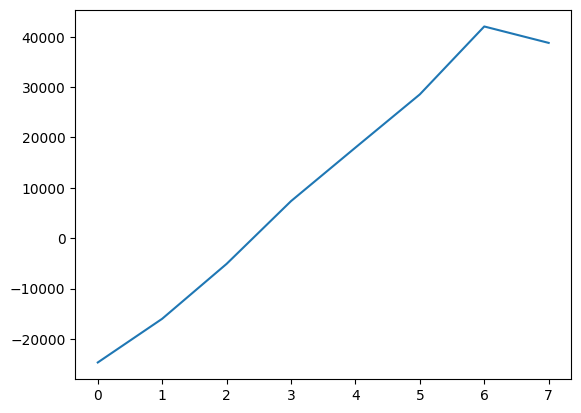

In [168]:
plt.plot(profits)

In [158]:
len(trades)

34

In [109]:
brokerage = 40
stt = 8000000*0.01/100
trs = 8*1e6*0.0021/100
sebi = 10
gst = (brokerage + sebi + trs)*18/100
stamp = 8*1e6*0.002/100

slippage = 8*1e6*12/1e4

final = brokerage + stt + trs + sebi + gst + stamp


In [112]:
cost_in_bps = 1e4*final/(8*1e6)

In [113]:
cost_in_bps + 10

11.52155

In [231]:
8*1e6*40/1e4

32000.0

In [ ]:
'''
silver bid ask midp -> implied spot -> 
silverM bid ask midp-> implied spot
'''

'''
5 + 5 -> 10bps -> 11.5

'''